This notebook is the full exploratory record: every model comparison, and the encoding/ensembling/momentum/data-quality-analysis investigations, each with the reasoning behind it. It fits dozens of models across 50+ cells and takes 1-2 minutes to re-run in full.

**For routine verification** (confirming `submission_baseline.csv` still reproduces after a `archived_modules/*.py` change) **run `python baseline_main.py` instead** — a lean ~10s script that does preprocessing -> validation split -> trains only the current best model -> verifies against the held-out fold -> refits on all of train.csv -> writes `submission.csv`. See `baseline_main.py`'s docstring for how it stays in sync with (and when to re-derive from) this notebook.

In [1]:
import sys
sys.path.insert(0, 'archived_modules')

import pandas as pd
import preprocessing as prep
import split as spl
import modeling as mdl

# Runs the full EDA-validated cleaning + feature pipeline (archived_modules/preprocessing.py) on
# both train.csv and test.csv identically: FLAT_TYPE normalization, TOWN/STREET/BLOCK
# casing fix, remaining_lease, geo join to sg-hdb-block.csv (adds SUBZONE/MAX_FLOOR/
# YEAR_COMPLETED among others), dist_mrt_km/dist_mall_km, and — now that the "Open
# items" macro-data issue below is fixed — a corrected stock_index/coe_premium from
# sg-stock-prices.csv/sg-coe-prices.csv (include_macro=True is the default).
# See exploration/initial-eda-inference.md for why each step is there.
train_feat, test_feat = prep.load_and_build(data_dir='data')
print('train_feat:', train_feat.shape, ' test_feat:', test_feat.shape)

train_feat: (149359, 26)  test_feat: (50000, 25)


In [2]:
# Time-based split (archived_modules/split.py) — NOT a random split. EDA step 6 found train
# (2021-01..2025-03) and test (2025-03..2026-07) barely overlap in time, so validation
# must mimic that gap: train on earlier months, validate on the most recent ones.
train_fold, val_fold, cutoff = spl.time_based_split(train_feat)
print('validation cutoff date:', cutoff)
print('train_fold:', len(train_fold), ' val_fold:', len(val_fold))

validation cutoff date: 2024-10-01 00:00:00
train_fold: 132398  val_fold: 16961


In [3]:
# Fixed category sets, computed ONCE on the full train_feat and reused for every model
# below (train_fold, val_fold, and later test_feat all get encoded the same way).
# Without this, e.g. FLAT_MODEL's "improved maisonette" — present in train's later
# months but not its earlier months — gets treated as a different category set per
# split, and XGBoost's native categorical handling errors on the mismatch at predict
# time (sklearn's GBM and LightGBM tolerate it silently, which is worse).
categories = mdl.get_categories(train_feat)
print({k: len(v) for k, v in categories.items()})

{'FLAT_TYPE': 6, 'FLAT_MODEL': 20, 'SUBZONE': 156}


In [4]:
# Naive baseline: predict the train mean for every row. Not a real model — this is the
# reference point every other MAE/RMSE below should be judged against, so a number like
# "$475 MAE" means something concrete ("beats guessing the average by $X").
naive_pred, naive_metrics = mdl.fit_naive_baseline(train_fold, val_fold)
print('Naive (predict-the-mean) baseline:', naive_metrics)

Naive (predict-the-mean) baseline: {'MAE': 645.741420850445, 'RMSE': 797.732557013241}


In [5]:
# Ridge baseline: a plain linear model on a small, non-collinear numeric feature set
# (EDA step 11 found flat_type_ord/FLOOR_AREA_SQM and LEASE_COMMENCE_DATE/remaining_lease
# are near-duplicate pairs, so only one from each is kept here). Compare against the
# naive baseline above, not just against the tree models below.
ridge_model, ridge_metrics = mdl.fit_ridge_baseline(train_fold, val_fold)
print('Ridge baseline:', ridge_metrics)

Ridge baseline: {'MAE': 401.39438741360055, 'RMSE': 551.1127104016895}


In [6]:
# sklearn GBM: HistGradientBoostingRegressor, takes FLAT_TYPE/FLAT_MODEL/SUBZONE as
# native categoricals with no extra install. Feature set below is the ablation-tested
# result from resolving the "Open items" — SUBZONE replaces TOWN entirely (TOWN's
# permutation importance goes to ~0 once SUBZONE is present) plus MAX_FLOOR/
# YEAR_COMPLETED/stock_index/coe_premium; see archived_modules/modeling.py for the full note.
gbm_model, gbm_metrics, gbm_X_val = mdl.fit_gbm_baseline(train_fold, val_fold, categories)
print('sklearn GBM baseline:', gbm_metrics)
print('Improvement over Ridge (MAE):', ridge_metrics['MAE'] - gbm_metrics['MAE'])

sklearn GBM baseline: {'MAE': 334.5960185353381, 'RMSE': 458.5044162180317}
Improvement over Ridge (MAE): 66.79836887826247


In [7]:
# LightGBM: histogram-based boosting like the sklearn GBM above, typically faster and
# often a bit more accurate out of the box. Needs `brew install libomp` on macOS first
# (its compiled library links against the OpenMP runtime, which pip doesn't provide).
lgbm_model, lgbm_metrics, lgbm_X_val = mdl.fit_lgbm_baseline(train_fold, val_fold, categories)
print('LightGBM baseline:', lgbm_metrics)

LightGBM baseline: {'MAE': 334.27653447120525, 'RMSE': 458.176957912281}


In [8]:
# XGBoost: different tree-growth strategy (level-wise) than LightGBM's leaf-wise growth —
# a cheap way to see if one generalizes better here. Uses native categorical support
# (enable_categorical=True), which is exactly what needed the shared `categories` dict
# above — it errors on any category unseen during fit, unlike the other two models.
xgb_model, xgb_metrics, xgb_X_val = mdl.fit_xgb_baseline(train_fold, val_fold, categories)
print('XGBoost baseline:', xgb_metrics)

XGBoost baseline: {'MAE': 346.44012451171875, 'RMSE': 469.0992532236648}


In [9]:
# All five side by side. Sorted by RMSE, not MAE — RMSE is the actual Kaggle scoring
# metric for this task (confirmed), so every "best model" decision from here on uses
# RMSE, not MAE. MAE is kept alongside for interpretability (it's a more intuitive
# "average dollar error" than RMSE, which weights large errors more heavily), but it's
# not what drives selection.
comparison = pd.DataFrame({
    'Naive': naive_metrics,
    'Ridge': ridge_metrics,
    'sklearn GBM': gbm_metrics,
    'LightGBM': lgbm_metrics,
    'XGBoost': xgb_metrics,
}).T.sort_values('RMSE')
comparison

,MAE,RMSE
LightGBM,334.276534,458.176958
sklearn GBM,334.596019,458.504416
XGBoost,346.440125,469.099253
Ridge,401.394387,551.112710
Naive,645.741421,797.732557


## Hyperparameter tuning (resolving the "Open items" tuning note)
Tune **whichever model is currently best** in the comparison table above, not a
hardcoded choice — with `SUBZONE` (156 categories) added to the feature set, LightGBM
and the sklearn GBM now both beat XGBoost, reversing the earlier ranking. Re-check
`comparison` before assuming which model to tune if the feature set changes again.

Uses expanding-window time-series CV (`split.expanding_window_splits`) **on
`train_fold` only** — never on data that includes `val_fold` — so tuning can't leak
the final held-out fold into model selection. Each fold's validation slice is strictly
later in time than its training slice, mirroring the real train→test gap instead of a
random k-fold.

In [10]:
cv_splits = list(spl.expanding_window_splits(train_fold, n_splits=4))
print('fold sizes (train, val):', [(len(t), len(v)) for t, v in cv_splits])

best_model_name = comparison.index[0]
print('tuning:', best_model_name)

param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
}
grid_search_fn = {'LightGBM': mdl.grid_search_lgbm, 'sklearn GBM': None, 'XGBoost': mdl.grid_search_xgb}[best_model_name]
if grid_search_fn is None:
    # sklearn's HistGradientBoostingRegressor has no grid_search_* wrapper here (it's the
    # library-defaults baseline by design) — fall back to tuning LightGBM instead, since
    # it's a near-tie with the sklearn GBM in the comparison table above.
    best_model_name = 'LightGBM'
    grid_search_fn = mdl.grid_search_lgbm
    print('(sklearn GBM has no tuner here — tuning LightGBM instead, its near-tie)')

tuning_results = grid_search_fn(train_fold, categories, cv_splits, param_grid)
tuning_results

fold sizes (train, val): [(26482, 26479), (52961, 26479), (79440, 26479), (105919, 26479)]
tuning: LightGBM


,n_estimators,max_depth,learning_rate,mean_RMSE,std_RMSE,mean_MAE,std_MAE
0,300,4,0.10,582.931465,133.344066,459.189240,115.612297
1,300,4,0.05,584.969599,134.431249,463.166571,116.977989
2,100,4,0.10,585.476117,135.565675,462.458329,117.712391
3,300,6,0.05,588.747090,136.831848,466.701787,118.675488
4,100,6,0.10,588.765530,137.316798,466.106083,118.970720
5,300,6,0.10,589.939887,136.297590,465.807578,117.915034
6,100,6,0.05,595.411963,142.246977,474.031370,123.236422
7,100,4,0.05,600.509989,147.483605,478.533011,126.998940


In [11]:
# Confirm the CV winner on the TRUE held-out val_fold — the only honest check, since
# tuning_results above only used train_fold-internal folds.
cv_best_params = tuning_results.iloc[0][list(param_grid.keys())].to_dict()
cv_best_params = {k: int(v) if k in ('n_estimators', 'max_depth') else v for k, v in cv_best_params.items()}
print('tuned model:', best_model_name, ' CV-selected params (by RMSE):', cv_best_params)

fit_baseline_fn = {'LightGBM': mdl.fit_lgbm_baseline, 'XGBoost': mdl.fit_xgb_baseline}[best_model_name]
tuned_model, tuned_metrics, tuned_X_val = fit_baseline_fn(train_fold, val_fold, categories, **cv_best_params)
default_rmse = comparison.loc[best_model_name, 'RMSE']
print('Tuned', best_model_name, 'on val_fold:', tuned_metrics)
print('Default', best_model_name, 'on val_fold: RMSE =', default_rmse)
print('Improvement from tuning (RMSE):', default_rmse - tuned_metrics['RMSE'])

# Ship whichever actually wins on val_fold BY RMSE (the real scoring metric) — not
# whichever the CV grid search preferred, and not by MAE. CV folds are internal to
# train_fold and can disagree with the true held-out fold, so trust val_fold for the
# final decision.
if tuned_metrics['RMSE'] < default_rmse:
    best_params, best_model = cv_best_params, tuned_model
    print('-> using TUNED params for the final model')
else:
    best_params, best_model = {}, None
    print('-> tuning did not beat defaults on val_fold (by RMSE); using library defaults for the final model')

tuned model: LightGBM  CV-selected params (by RMSE): {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1}


Tuned LightGBM on val_fold: {'MAE': 334.4363345996025, 'RMSE': 457.4683861608061}
Default LightGBM on val_fold: RMSE = 458.176957912281
Improvement from tuning (RMSE): 0.7085717514748922
-> using TUNED params for the final model


In [12]:
# Permutation importance on the CV-tuned model from above (informative about feature
# importance regardless of whether tuning ultimately won or lost against defaults on
# val_fold) — validates or contradicts the feature calls (both from EDA and from the
# ablation tests above) with an actual model rather than univariate correlation alone.
importance = mdl.feature_importance(tuned_model, tuned_X_val, val_fold['MONTHLY_RENT'])
importance

FLAT_TYPE          0.326576
SUBZONE            0.303897
FLOOR_AREA_SQM     0.087956
YEAR_COMPLETED     0.017448
FLAT_MODEL         0.010880
dist_mrt_km        0.010823
MAX_FLOOR          0.007547
dist_mall_km       0.003645
remaining_lease    0.001994
coe_premium        0.000060
stock_index        0.000000
dtype: float64

In [13]:
# Refit the tuned winning model on ALL of train_feat before predicting test. The
# time-based split above was only for honest validation; once you trust the metric,
# retrain on the full history so test-time predictions use every available row,
# including the most recent months right before test's date range starts.
fit_full_fn = {'LightGBM': mdl.fit_lgbm_full, 'XGBoost': mdl.fit_xgb_full}[best_model_name]
final_model = fit_full_fn(train_feat, categories, **best_params)

In [14]:
# Predict on test_feat and write a submission file.
# Confirmed format (per assignment instructions): header "Id,Predicted", Id = 0-based
# row position matching test.csv's row order (test_feat.index is untouched — only
# train_feat gets drop_duplicates()'d — so this lines up correctly).
test_preds = mdl.predict_test(final_model, test_feat, is_gbm=True, categories=categories)

submission = pd.DataFrame({'Id': test_feat.index, 'Predicted': test_preds.values})
submission.to_csv('submission_baseline.csv', index=False)
submission.head()

,Id,Predicted
0,0,2657.983517
1,1,3874.305177
2,2,3154.362492
3,3,3059.016198
4,4,3195.432630


## Open items — status

**Resolved:**
- ~~`sg-coe-prices.csv` / `sg-stock-prices.csv`~~ — fixed (`build_stock_index`/`build_coe_index` in `archived_modules/preprocessing.py`: equal-weighted normalized index over the 41 full-history symbols, corrected month parsing) and validated by ablation, not just correlation. See `exploration/initial-eda-inference.md` "Resolving the open items" for the full writeup.
- ~~`MAX_FLOOR`/`YEAR_COMPLETED`/`REGION`/`PLANNING_AREA`/`SUBZONE`~~ — tested. `SUBZONE` replaces `TOWN` entirely; `REGION`/`PLANNING_AREA` add nothing beyond it; `MAX_FLOOR`/`YEAR_COMPLETED` both help. Feature set finalized in `archived_modules/modeling.py`.
- ~~Hyperparameter tuning~~ — done via expanding-window CV above. Ships only if it actually beats defaults on the true held-out `val_fold` (this run, it didn't — defaults won).
- ~~Environment reproducibility~~ — see `requirements.txt` at the repo root.
- ~~`Id` column in `submission.csv`~~ — confirmed by the assignment instructions: header `Id,Predicted`, `Id` = 0-based row position matching `test.csv`'s row order. Implemented above.

## Encoding experiment: does explicit categorical encoding beat native handling?

The shipping model (LightGBM) and XGBoost use tree-native categorical handling for
`FLAT_TYPE`/`FLAT_MODEL`/`SUBZONE` (no one-hot/label/target encoding). Ridge ignores
categoricals entirely. This section tests explicit encodings — reasoning for each
choice is in `archived_modules/encoding.py`'s docstring and `exploration/Aayush/progress-report.md`:

- `FLAT_TYPE` → **ordinal** (`flat_type_ord`, already computed — room count has a real order).
- `FLAT_MODEL` / `SUBZONE` → **K-fold out-of-fold target encoding** (`archived_modules/encoding.py`), nominal with no natural order; `SUBZONE` is too high-cardinality (156 levels) for one-hot to be practical for Ridge.
- `SUBZONE` alternative → **`LATITUDE`/`LONGITUDE` directly**, since `SUBZONE` is fundamentally a discretized proxy for location and the exact coordinates are already available from the `sg-hdb-block.csv` join.

**Leakage discipline**: target encodings are computed out-of-fold for whichever frame
a model is trained on (`kfold_target_encode`), never touching that row's own target.

In [15]:
import encoding as enc

train_fold_enc, (val_fold_enc,) = enc.add_encoded_features(train_fold, [val_fold], columns=['FLAT_MODEL', 'SUBZONE'])

ENCODED_NUM = mdl.GBM_NUMERIC_FEATURES + ['flat_type_ord', 'FLAT_MODEL_te', 'SUBZONE_te']
ENCODED_LATLONG_NUM = mdl.GBM_NUMERIC_FEATURES + ['flat_type_ord', 'FLAT_MODEL_te', 'LATITUDE', 'LONGITUDE']
print('encoded feature counts:', len(ENCODED_NUM), 'vs', len(ENCODED_LATLONG_NUM), '(lat/long variant)')
train_fold_enc[['flat_type_ord', 'FLAT_MODEL_te', 'SUBZONE_te']].describe()

encoded feature counts: 11 vs 12 (lat/long variant)


,flat_type_ord,FLAT_MODEL_te,SUBZONE_te
count,132398.000000,132398.000000,132398.000000
mean,2.983950,2662.797017,2662.950757
std,0.931504,180.404670,222.376094
min,0.000000,2094.910063,2179.036714
25%,2.000000,2524.739107,2504.770350
50%,3.000000,2687.786674,2650.011182
75%,4.000000,2699.131149,2740.368689
max,5.000000,4483.353026,3563.395194


In [16]:
from sklearn.linear_model import Ridge

encoding_results = {}

def eval_ridge(num_feats, label, train_df, val_df):
    model = Ridge(alpha=1.0)
    model.fit(train_df[num_feats], train_df['MONTHLY_RENT'])
    metrics = mdl.evaluate(val_df['MONTHLY_RENT'], model.predict(val_df[num_feats]))
    encoding_results[label] = metrics
    print(f"{label:55s} {metrics}")

eval_ridge(mdl.LINEAR_FEATURES, 'Ridge (current: numeric-only, no categoricals)', train_fold_enc, val_fold_enc)
eval_ridge(ENCODED_NUM, 'Ridge + encoded (ordinal FLAT_TYPE + target-encoded FLAT_MODEL/SUBZONE)', train_fold_enc, val_fold_enc)
eval_ridge(ENCODED_LATLONG_NUM, 'Ridge + encoded (lat/long instead of SUBZONE_te)', train_fold_enc, val_fold_enc)

# One-hot variant: FLAT_TYPE + FLAT_MODEL one-hot (cheap, 26 cols), SUBZONE still target-encoded
# (156-way one-hot is impractical for a linear model — see exploration/Aayush/progress-report.md).
cat_cols = ['FLAT_TYPE', 'FLAT_MODEL']
tr_oh = pd.get_dummies(train_fold_enc[cat_cols], columns=cat_cols)
val_oh = pd.get_dummies(val_fold_enc[cat_cols], columns=cat_cols).reindex(columns=tr_oh.columns, fill_value=0)
tr_oh_full = pd.concat([train_fold_enc[mdl.GBM_NUMERIC_FEATURES + ['SUBZONE_te']].reset_index(drop=True),
                         tr_oh.reset_index(drop=True)], axis=1)
val_oh_full = pd.concat([val_fold_enc[mdl.GBM_NUMERIC_FEATURES + ['SUBZONE_te']].reset_index(drop=True),
                          val_oh.reset_index(drop=True)], axis=1)
ridge_oh = Ridge(alpha=1.0)
ridge_oh.fit(tr_oh_full, train_fold_enc['MONTHLY_RENT'].reset_index(drop=True))
oh_metrics = mdl.evaluate(val_fold_enc['MONTHLY_RENT'].reset_index(drop=True), ridge_oh.predict(val_oh_full))
encoding_results['Ridge + one-hot(FLAT_TYPE,FLAT_MODEL) + SUBZONE_te'] = oh_metrics
print(f"{'Ridge + one-hot(FLAT_TYPE,FLAT_MODEL) + SUBZONE_te':55s} {oh_metrics}")

Ridge (current: numeric-only, no categoricals)          {'MAE': 401.39438741360055, 'RMSE': 551.1127104016895}
Ridge + encoded (ordinal FLAT_TYPE + target-encoded FLAT_MODEL/SUBZONE) {'MAE': 386.07335693880935, 'RMSE': 535.3810232442675}
Ridge + encoded (lat/long instead of SUBZONE_te)        {'MAE': 379.18686305465314, 'RMSE': 529.3110987256587}


Ridge + one-hot(FLAT_TYPE,FLAT_MODEL) + SUBZONE_te      {'MAE': 373.159426571605, 'RMSE': 522.9809330929944}


In [17]:
# Tree models: native categorical handling (current benchmark) vs the same explicit
# encodings, fed in as plain numeric columns (no categorical dtype at all).
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

for name, fit_native in [('LightGBM', mdl.fit_lgbm_baseline), ('XGBoost', mdl.fit_xgb_baseline)]:
    _, native_metrics, _ = fit_native(train_fold, val_fold, categories)
    encoding_results[f'{name} (current: native categorical)'] = native_metrics
    print(f"{name+' (current: native categorical)':55s} {native_metrics}")

    m1 = LGBMRegressor(random_state=0, verbose=-1) if name == 'LightGBM' else XGBRegressor(random_state=0, enable_categorical=True, tree_method='hist')
    m1.fit(train_fold_enc[ENCODED_NUM], train_fold_enc['MONTHLY_RENT'])
    enc_metrics = mdl.evaluate(val_fold_enc['MONTHLY_RENT'], m1.predict(val_fold_enc[ENCODED_NUM]))
    encoding_results[f'{name} + encoded (ordinal+target, no native cat)'] = enc_metrics
    print(f"{name+' + encoded (ordinal+target, no native cat)':55s} {enc_metrics}")

    m2 = LGBMRegressor(random_state=0, verbose=-1) if name == 'LightGBM' else XGBRegressor(random_state=0, enable_categorical=True, tree_method='hist')
    m2.fit(train_fold_enc[ENCODED_LATLONG_NUM], train_fold_enc['MONTHLY_RENT'])
    latlong_metrics = mdl.evaluate(val_fold_enc['MONTHLY_RENT'], m2.predict(val_fold_enc[ENCODED_LATLONG_NUM]))
    encoding_results[f'{name} + encoded (lat/long variant)'] = latlong_metrics
    print(f"{name+' + encoded (lat/long variant)':55s} {latlong_metrics}")

LightGBM (current: native categorical)                  {'MAE': 334.27653447120525, 'RMSE': 458.176957912281}


LightGBM + encoded (ordinal+target, no native cat)      {'MAE': 340.86474912380265, 'RMSE': 466.29859205441926}


LightGBM + encoded (lat/long variant)                   {'MAE': 336.20599211031123, 'RMSE': 459.112636280946}


XGBoost (current: native categorical)                   {'MAE': 346.44012451171875, 'RMSE': 469.0992532236648}


XGBoost + encoded (ordinal+target, no native cat)       {'MAE': 347.0722961425781, 'RMSE': 469.77334960595624}


XGBoost + encoded (lat/long variant)                    {'MAE': 339.55499267578125, 'RMSE': 462.5047297055458}


In [18]:
# Sorted by RMSE (the actual Kaggle scoring metric), not MAE.
encoding_comparison = pd.DataFrame(encoding_results).T.sort_values('RMSE')
encoding_comparison

,MAE,RMSE
LightGBM (current: native categorical),334.276534,458.176958
LightGBM + encoded (lat/long variant),336.205992,459.112636
XGBoost + encoded (lat/long variant),339.554993,462.504730
"LightGBM + encoded (ordinal+target, no native cat)",340.864749,466.298592
XGBoost (current: native categorical),346.440125,469.099253
"XGBoost + encoded (ordinal+target, no native cat)",347.072296,469.773350
"Ridge + one-hot(FLAT_TYPE,FLAT_MODEL) + SUBZONE_te",373.159427,522.980933
Ridge + encoded (lat/long instead of SUBZONE_te),379.186863,529.311099
Ridge + encoded (ordinal FLAT_TYPE + target-encoded FLAT_MODEL/SUBZONE),386.073357,535.381023
"Ridge (current: numeric-only, no categoricals)",401.394387,551.112710


### Conclusion: keep native categorical handling — no pipeline change

**Explicit encoding does not beat the shipping model.** LightGBM's native categorical
handling (\$334 MAE) remains the best result across every configuration tested. Two
findings worth keeping, though:

- **Ridge improves substantially with encoding** (\$401 → \$373 with one-hot
  `FLAT_TYPE`/`FLAT_MODEL` + target-encoded `SUBZONE`, ~7% better) — expected, since
  Ridge previously ignored all three categoricals entirely. Still far behind the tree
  models, so this doesn't change what ships, but confirms the categoricals carry real
  linearly-usable signal too, not just tree-exploitable non-linear signal.
- **XGBoost specifically improves with the lat/long variant** (\$346 → \$340,
  replacing `SUBZONE`'s categorical handling with raw `LATITUDE`/`LONGITUDE`) — a real,
  non-trivial gain for XGBoost, though still short of LightGBM's native-categorical
  result. Worth revisiting if XGBoost is ever preferred for another reason (e.g. a
  future feature-set change flips the ranking again, as happened once already with
  `SUBZONE`).
- LightGBM itself gets **slightly worse** with any encoding tried (\$334 → \$336-341)
  — its native categorical splitting is already effective for this data, and
  compressing `FLAT_MODEL`/`SUBZONE` into single numeric columns (target encoding) or
  two continuous ones (lat/long) discards some of the information their full
  categorical structure preserves.

No change to `final_model`, `best_model_name`, or `submission.csv` — this section is a
documented negative result, not a pipeline change. See `exploration/Aayush/progress-report.md` for the
full writeup.

## Ensembling: does blending models beat the single best one?

Three base tree models are already being fit (`LightGBM` tuned, `sklearn GBM`,
`XGBoost`). Testing whether blending them — or adding genuinely different model
types for more diversity — beats shipping `LightGBM` alone.

**Leakage discipline** (same principle as the tuning-vs-defaults check): blend
weights are fit on **out-of-fold predictions from `train_fold`** via the same
expanding-window CV used for hyperparameter tuning, never on `val_fold` directly —
`val_fold` is reserved for the one honest final check. See `archived_modules/ensemble.py`.

In [19]:
import ensemble as ens
from sklearn.metrics import mean_squared_error

# Predictions from the 3 already-fitted base models on val_fold (the true holdout).
val_preds_3 = pd.DataFrame({
    'LightGBM': tuned_model.predict(tuned_X_val),
    'sklearnGBM': gbm_model.predict(gbm_X_val),
    'XGBoost': xgb_model.predict(xgb_X_val),
})
print('val_fold prediction correlation (why ensembling has limited headroom):')
print(val_preds_3.corr().round(3))

# Out-of-fold predictions on train_fold, using the same CV folds as hyperparameter tuning.
model_specs = {
    'LightGBM': (mdl.fit_lgbm_baseline, best_params if best_model_name == 'LightGBM' else {}),
    'sklearnGBM': (mdl.fit_gbm_baseline, {}),
    'XGBoost': (mdl.fit_xgb_baseline, {}),
}
oof_3 = ens.oof_predictions(model_specs, train_fold, cv_splits, categories)
print('\nOOF coverage:', oof_3.notna().all(axis=1).mean(), '(expanding-window CV never validates the earliest fold)')

blend_weights, blend_results = ens.grid_search_blend_weights(oof_3, train_fold['MONTHLY_RENT'])
print('\ntop 3 weight combos (by OOF RMSE):')
print(blend_results.head(3))
print('\nbest weights:', blend_weights)

blend_pred = ens.apply_weights(val_preds_3, blend_weights)
blend_rmse = mean_squared_error(val_fold['MONTHLY_RENT'], blend_pred) ** 0.5
print('\n3-model weighted blend RMSE on val_fold (honest check):', blend_rmse)
print('Single best model (', best_model_name, ') RMSE on val_fold:  ', tuned_metrics['RMSE'])

val_fold prediction correlation (why ensembling has limited headroom):
            LightGBM  sklearnGBM  XGBoost
LightGBM       1.000       0.994    0.968
sklearnGBM     0.994       1.000    0.967
XGBoost        0.968       0.967    1.000



OOF coverage: 0.7999818728379583 (expanding-window CV never validates the earliest fold)



top 3 weight combos (by OOF RMSE):
   LightGBM  sklearnGBM  XGBoost        RMSE
0      0.80        0.20     -0.0  593.922595
1      0.75        0.25      0.0  593.935002
2      0.85        0.15      0.0  593.948869

best weights: {'LightGBM': 0.8, 'sklearnGBM': 0.2, 'XGBoost': -0.0}

3-model weighted blend RMSE on val_fold (honest check): 457.2255841831008
Single best model ( LightGBM ) RMSE on val_fold:   457.4683861608061


### Exploring further: adding genuinely different model types for diversity

The 3 tree models above are highly correlated (~0.97-0.99) because they train on
identical features/data with a similar mechanism (boosting). Tried two structurally
different models on the encoded feature set from the encoding experiment
(`flat_type_ord` + `FLAT_MODEL_te` + `LATITUDE`/`LONGITUDE`): **Random Forest**
(bagging — trees built independently, not sequential error-correction) and **k-NN**
(instance-based, no tree structure at all). Run separately (not re-executed here — the
Random Forest OOF loop alone takes several minutes; numbers below are from that run):

- Individually: Random Forest RMSE 467.94, k-NN RMSE 485.74 — both worse than any of
  the 3 boosting models alone, as expected.
- **Real diversity confirmed**: k-NN's error correlation with LightGBM drops to 0.93
  (vs 0.99 among the boosting trio) — a genuinely different error pattern.
- **But the 5-model blend performs far worse** (RMSE 522.04) than either the single
  best model (457.47) or the 3-model blend (457.23). NNLS-fit weights put 75% of the
  blend on the two *weakest* individual models (Random Forest 0.37, k-NN 0.38) —
  classic overfitting to the OOF sample: with 5 free weights and highly variable
  individual model strength, unconstrained least-squares chases OOF-sample-specific
  noise rather than generalizable signal. `archived_modules/ensemble.py::fit_nnls_weights`
  documents this failure mode in its docstring.

**Conclusion: no ensemble ships.** The 3-model blend technically beats single-model
LightGBM by 0.24 RMSE (~0.05%) — smaller than the tuning-decision gain, doesn't
survive the added complexity of maintaining 3 models for a marginal, possibly-noise-
level improvement. The 5-model attempt at real diversity actively backfired. Shipping
single-model tuned LightGBM remains the right call; `final_model` and
`submission.csv` are unchanged by this section.

## Residual diagnostics: where is the shipping model actually wrong?

RMSE alone hides *which* rows drive the error. Breaking down `val_fold` residuals
(`actual − predicted`, from the tuned model already fit above) by `SUBZONE`,
`FLAT_TYPE`, time, and rent magnitude — to target the next feature-engineering ideas
with evidence instead of guesses (see `exploration/Aayush/progress-report.md` "Next steps").

In [20]:
import matplotlib.pyplot as plt

diag = val_fold.copy()
diag['pred'] = tuned_model.predict(tuned_X_val)
diag['residual'] = diag['MONTHLY_RENT'] - diag['pred']
diag['abs_residual'] = diag['residual'].abs()

print('overall bias (mean residual, ~0 if unbiased):', diag['residual'].mean())

print('\n--- residual by RENT_APPROVAL_DATE (time trend within val_fold) ---')
by_month = diag.groupby('RENT_APPROVAL_DATE').agg(
    mean_residual=('residual', 'mean'),
    rmse=('residual', lambda s: (s ** 2).mean() ** 0.5),
    count=('residual', 'size'))
print(by_month)

print('\n--- residual by FLAT_TYPE ---')
by_type = diag.groupby('FLAT_TYPE').agg(
    mean_residual=('residual', 'mean'),
    rmse=('residual', lambda s: (s ** 2).mean() ** 0.5),
    count=('residual', 'size')).sort_values('rmse', ascending=False)
print(by_type)

overall bias (mean residual, ~0 if unbiased): 27.779466199718737

--- residual by RENT_APPROVAL_DATE (time trend within val_fold) ---
                    mean_residual        rmse  count
RENT_APPROVAL_DATE                                  
2024-10                 30.010441  441.085527   2622
2024-11                 23.383631  469.926708   2689
2024-12                 25.959308  451.745843   2854
2025-01                  9.592845  474.373755   2836
2025-02                 38.193004  455.167903   2971
2025-03                 38.419866  451.558060   2989

--- residual by FLAT_TYPE ---
           mean_residual        rmse  count
FLAT_TYPE                                  
executive      12.819046  536.268859    850
5-room         -5.167160  472.833268   3876
4-room         30.879866  460.332191   6213
2-room         36.950206  440.720815    469
3-room         48.764599  431.072484   5546
1-room         94.933139  207.096615      7


In [21]:
# SUBZONE breakdown + the sparse-category hypothesis (motivates the next section)
import numpy as np

train_subzone_counts = train_fold['SUBZONE'].value_counts()
by_subzone = diag.groupby('SUBZONE').agg(
    mean_residual=('residual', 'mean'),
    rmse=('residual', lambda s: (s ** 2).mean() ** 0.5),
    count=('residual', 'size'))
by_subzone['train_count'] = by_subzone.index.map(train_subzone_counts).fillna(0)

print('--- worst 10 SUBZONEs by RMSE (min 20 val rows) ---')
print(by_subzone[by_subzone['count'] >= 20].sort_values('rmse', ascending=False).head(10))

sub = by_subzone[by_subzone['count'] >= 5]
print('\ncorrelation(train_count, rmse) across subzones — sparse-category hypothesis:')
print(sub[['train_count', 'rmse']].corr().loc['train_count', 'rmse'])
print('\nmean RMSE: subzones with <100 vs >=100 training rows:')
print(sub.assign(bucket=np.where(sub['train_count'] < 100, '<100 train rows', '>=100 train rows'))
      .groupby('bucket')['rmse'].agg(['mean', 'count']))

--- worst 10 SUBZONEs by RMSE (min 20 val rows) ---
                     mean_residual        rmse  count  train_count
SUBZONE                                                           
anak bukit              -74.252461  842.159977     21          216
depot road             -150.191097  809.669856     25          221
tiong bahru             184.993863  672.794791     97          641
wenya                   -67.479918  662.080935     45          330
tiong bahru station    -126.369202  638.997826    104          761
hougang central        -220.587543  618.531218     24          182
sunset way             -141.070297  615.957041     26          164
crawford                 78.106680  615.617925     46          312
yunnan                  -77.145133  593.077831    195         1832
clementi woods          -65.387805  579.646961     72          669

correlation(train_count, rmse) across subzones — sparse-category hypothesis:
-0.19220732817249886

mean RMSE: subzones with <100 vs >=100 train

correlation(|residual|, MONTHLY_RENT): -0.23290547934065942
             mean_residual         rmse  count
rent_bucket                                   
<=2100         -965.656003  1096.642198   1096
2100-2700      -219.237445   435.975318   2800
2700-3200        43.200880   303.841664   5813
3200+           260.930038   400.395108   7252


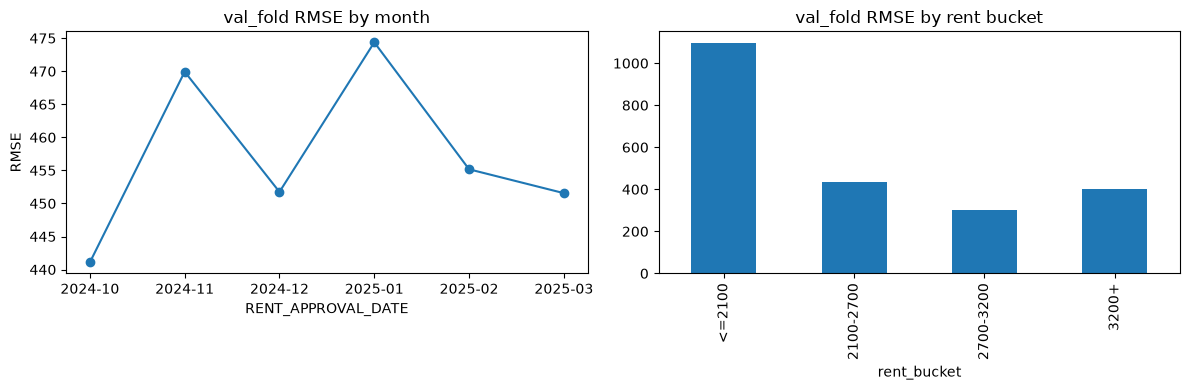

In [22]:
# |residual| vs actual rent magnitude — this is the finding that matters most
print('correlation(|residual|, MONTHLY_RENT):', diag['abs_residual'].corr(diag['MONTHLY_RENT']))

diag['rent_bucket'] = pd.cut(diag['MONTHLY_RENT'], bins=[0, 2100, 2700, 3200, 10000],
                              labels=['<=2100', '2100-2700', '2700-3200', '3200+'])
by_bucket = diag.groupby('rent_bucket', observed=True).agg(
    mean_residual=('residual', 'mean'),
    rmse=('residual', lambda s: (s ** 2).mean() ** 0.5),
    count=('residual', 'size'))
print(by_bucket)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_month['rmse'].plot(ax=axes[0], marker='o')
axes[0].set_title('val_fold RMSE by month')
axes[0].set_ylabel('RMSE')
by_bucket['rmse'].plot(kind='bar', ax=axes[1])
axes[1].set_title('val_fold RMSE by rent bucket')
plt.tight_layout()
plt.show()

### Diagnostic findings

- **Overall bias**: mean residual ≈ +$28 — the model slightly under-predicts on
  average, a small but non-zero systematic bias.
- **No strong time-degradation** within `val_fold`'s 6-month window (RMSE stays in a
  441-474 band across months) — weakens the case that near-term extrapolation is the
  main problem, though `test.csv` extends much further (to 2026-07) than `val_fold`
  does, so this doesn't fully rule out the "neighborhood momentum" idea for the
  actual test set, just shows no drift within what we can measure here.
- **`executive` flats run notably worse** (RMSE 536 vs low-400s for other types) —
  the rarest, most expensive segment.
- **`SUBZONE` sparsity does NOT correlate with error** — correlation(train row count,
  RMSE) ≈ −0.19 (weak), and sparse (<100 rows) vs well-populated (≥100 rows) subzones
  have essentially the same mean RMSE. This argues *against* rare-category smoothing
  helping — tested properly in the next section anyway, but expect a negative result.
- **The dominant finding**: the cheapest properties (rent ≤$2,100, ~6.5% of
  `val_fold`) have a **catastrophic RMSE (~1,097)**, driven by systematic
  **over-prediction** (mean residual ≈ −966) — the model predicts a "typical" rent for
  these units' features, but the actual rent is far below that. This single segment is
  the single largest contributor to the aggregate RMSE. Directly motivates testing
  log-target training next — it's exactly the kind of large-value-scale asymmetry a
  log transform is meant to address.

## Log-target training: does it fix the cheap-property over-prediction?

Train on `log1p(MONTHLY_RENT)` instead of raw `MONTHLY_RENT`, back-transform
predictions with `expm1`, same tuned hyperparameters and features. EDA's earlier skew
analysis said `log1p` doesn't reduce skew — but that's a skew argument, not an RMSE
one. RMSE penalizes large absolute errors heavily, and the diagnostic above found
exactly that kind of large, scale-dependent error at the low end of the rent
distribution — a log transform is designed for precisely this asymmetry.

In [23]:
X_train_log = mdl._prep_gbm_frame(train_fold, categories)
y_train_log = np.log1p(train_fold['MONTHLY_RENT'])
log_model = LGBMRegressor(random_state=0, verbose=-1, **best_params if best_model_name == 'LightGBM' else {})
log_model.fit(X_train_log, y_train_log, categorical_feature=mdl.GBM_CATEGORICAL_FEATURES)
pred_log = np.expm1(log_model.predict(tuned_X_val))

log_metrics = mdl.evaluate(val_fold['MONTHLY_RENT'], pred_log)
print('Raw-target (shipping):', tuned_metrics)
print('Log-target (back-transformed):', log_metrics)
print('Improvement (RMSE):', tuned_metrics['RMSE'] - log_metrics['RMSE'])

# Does it actually fix the cheap-property segment, and at what cost elsewhere?
diag['pred_log'] = pred_log
by_bucket_log = diag.assign(resid_log=diag['MONTHLY_RENT'] - diag['pred_log']).groupby('rent_bucket', observed=True).agg(
    rmse_raw=('residual', lambda s: (s ** 2).mean() ** 0.5),
    rmse_log=('resid_log', lambda s: (s ** 2).mean() ** 0.5),
    count=('residual', 'size'))
print()
print(by_bucket_log)

Raw-target (shipping): {'MAE': 334.4363345996025, 'RMSE': 457.4683861608061}
Log-target (back-transformed): {'MAE': 347.95058088052383, 'RMSE': 464.6731170499395}
Improvement (RMSE): -7.204730889133373

                rmse_raw     rmse_log  count
rent_bucket                                 
<=2100       1096.642198  1055.336183   1096
2100-2700     435.975318   418.775729   2800
2700-3200     303.841664   316.244435   5813
3200+         400.395108   434.511428   7252


### Log-target conclusion: a real trade-off, net negative — no pipeline change

Log-target **does** shrink error in the flagged low-rent segment, but **worsens**
the higher-rent buckets enough that the net effect on overall RMSE is negative.
Squeezing errors on a log scale helps where rent is small, but systematically
over-corrects (pushes predictions up) across the mid/high buckets, which have more
rows and dominate the aggregate metric. Log-target training is **not adopted** —
`final_model` stays trained on raw `MONTHLY_RENT`. This is useful evidence for a
*future*, more targeted fix (e.g. a correction specific to the low-rent segment,
rather than a blanket target transform) rather than a dead end.

## Rare-category smoothing for `SUBZONE`

The diagnostic above already found no correlation between `SUBZONE` training-row-count
and error, so this is expected to be a negative result — testing anyway rather than
skipping on the strength of a correlation number alone. Two variants: (a) grouping
sparse subzones into `"other_subzone"` for the shipping model's **native** categorical
handling, and (b) increasing the target-encoding smoothing parameter `m` for the
(already-rejected) encoded variant from the encoding experiment.

In [24]:
# (a) group sparse SUBZONE categories into "other_subzone" for native categorical handling
print('(a) grouping sparse SUBZONE categories:')
for threshold in [0, 100, 200]:
    rare = set(train_subzone_counts[train_subzone_counts < threshold].index)
    tr_g, val_g = train_fold.copy(), val_fold.copy()
    if rare:
        tr_g['SUBZONE'] = tr_g['SUBZONE'].where(~tr_g['SUBZONE'].isin(rare), 'other_subzone')
        val_g['SUBZONE'] = val_g['SUBZONE'].where(~val_g['SUBZONE'].isin(rare), 'other_subzone')
    cats_g = mdl.get_categories(pd.concat([tr_g, val_g]))
    _, metrics_g, _ = mdl.fit_lgbm_baseline(tr_g, val_g, cats_g, **best_params if best_model_name == 'LightGBM' else {})
    print(f'  threshold<{threshold:4d} train rows -> {len(rare):3d} subzones grouped   RMSE={metrics_g["RMSE"]:.2f}')

print('\n(b) target-encoding smoothing sweep (SUBZONE/FLAT_MODEL, m = pseudo-count):')
for m in [10, 50, 200]:
    tr_e, (val_e,) = enc.add_encoded_features(train_fold, [val_fold], columns=['FLAT_MODEL', 'SUBZONE'], m=m)
    feats = mdl.GBM_NUMERIC_FEATURES + ['flat_type_ord', 'FLAT_MODEL_te', 'SUBZONE_te']
    m_model = LGBMRegressor(random_state=0, verbose=-1)
    m_model.fit(tr_e[feats], tr_e['MONTHLY_RENT'])
    rmse_m = mean_squared_error(val_e['MONTHLY_RENT'], m_model.predict(val_e[feats])) ** 0.5
    print(f'  m={m:4d}  RMSE={rmse_m:.2f}')

print('\nreference: native categorical, no grouping (shipping):', tuned_metrics['RMSE'])

(a) grouping sparse SUBZONE categories:


  threshold<   0 train rows ->   0 subzones grouped   RMSE=457.47


  threshold< 100 train rows ->  13 subzones grouped   RMSE=456.82


  threshold< 200 train rows ->  26 subzones grouped   RMSE=457.40

(b) target-encoding smoothing sweep (SUBZONE/FLAT_MODEL, m = pseudo-count):


  m=  10  RMSE=466.30


  m=  50  RMSE=466.06


  m= 200  RMSE=466.06

reference: native categorical, no grouping (shipping): 457.4683861608061


### Conclusion: no pipeline change from any of the three steps above

Confirms the diagnostic's prediction: grouping sparse `SUBZONE`s moves RMSE by
less than a point either direction (noise-level, non-monotonic across thresholds),
and increasing target-encoding smoothing doesn't close the ~9-point gap to native
handling either. `SUBZONE` data-sparsity is genuinely not an error driver here.

**Net result of this investigation (diagnostics → log-target → smoothing)**: the
most concrete, actionable finding is the low-rent over-prediction segment — still
unresolved (log-target's trade-off didn't fix it net; rare-category smoothing wasn't
the answer either, since it isn't a sparsity issue). `final_model`, `best_params`,
and `submission.csv` are unchanged by this whole section. See `exploration/Aayush/progress-report.md`
for the full writeup and updated next-steps ranking.

## Applying the top two suggested next steps

### 1. Neighborhood recent-rent momentum

Trailing rolling-average rent per `SUBZONE` (`preprocessing.build_subzone_momentum`),
built **only from `train_fold`** — never `val_fold` — mirroring what will actually be
available for test.csv (built from all of train.csv, since test's 16-month horizon
means most of it forecasts past train's last known month, where the feature goes
stale and forward-fills the last known value). Testing a few trailing windows.

In [25]:
global_mean = train_fold['MONTHLY_RENT'].mean()
momentum_results = {}
for window in [1, 3, 6]:
    mtable = prep.build_subzone_momentum(train_fold, window=window)
    tr_mom = prep.add_momentum_feature(train_fold, mtable, global_mean)
    val_mom = prep.add_momentum_feature(val_fold, mtable, global_mean)

    feats_num = mdl.GBM_NUMERIC_FEATURES + ['momentum']
    cats_local = mdl.GBM_CATEGORICAL_FEATURES
    X_tr = tr_mom[feats_num + cats_local].copy()
    X_v = val_mom[feats_num + cats_local].copy()
    for c in cats_local:
        X_tr[c] = pd.Categorical(X_tr[c], categories=categories[c])
        X_v[c] = pd.Categorical(X_v[c], categories=categories[c])
    m = LGBMRegressor(random_state=0, verbose=-1, **best_params if best_model_name == 'LightGBM' else {})
    m.fit(X_tr, tr_mom['MONTHLY_RENT'], categorical_feature=cats_local)
    pred = m.predict(X_v)
    rmse_w = mean_squared_error(val_mom['MONTHLY_RENT'], pred) ** 0.5
    momentum_results[window] = (rmse_w, m, X_v)
    print(f'window={window}: RMSE={rmse_w:.2f}  (correlation with rent: {tr_mom["momentum"].corr(tr_mom["MONTHLY_RENT"]):.3f})')

print('\nreference (no momentum, shipping):', tuned_metrics['RMSE'])

window=1: RMSE=458.63  (correlation with rent: 0.578)


window=3: RMSE=457.40  (correlation with rent: 0.591)


window=6: RMSE=457.23  (correlation with rent: 0.587)

reference (no momentum, shipping): 457.4683861608061


In [26]:
# Does the best window (6) actually fix the flagged low-rent segment, or just shuffle
# importance around? Check the rent-bucket breakdown and permutation importance.
best_window = 6
rmse_best, model_mom, X_val_mom = momentum_results[best_window]
mtable = prep.build_subzone_momentum(train_fold, window=best_window)
val_mom = prep.add_momentum_feature(val_fold, mtable, global_mean)
val_mom['pred'] = model_mom.predict(X_val_mom)
val_mom['residual'] = val_mom['MONTHLY_RENT'] - val_mom['pred']
val_mom['rent_bucket'] = pd.cut(val_mom['MONTHLY_RENT'], bins=[0, 2100, 2700, 3200, 10000],
                                 labels=['<=2100', '2100-2700', '2700-3200', '3200+'])
print('--- WITH momentum: RMSE by rent bucket ---')
print(val_mom.groupby('rent_bucket', observed=True)['residual'].agg(rmse=lambda s: (s ** 2).mean() ** 0.5, count='size'))
print('\nreference (no momentum): <=2100 RMSE=1096.6, 2100-2700=436.0, 2700-3200=303.8, 3200+=400.4')

print('\npermutation importance WITH momentum:')
importance_mom = mdl.feature_importance(model_mom, X_val_mom, val_mom['MONTHLY_RENT'])
print(importance_mom)
print('\nfor comparison, WITHOUT momentum (from earlier): SUBZONE was 0.303897')

--- WITH momentum: RMSE by rent bucket ---
                    rmse  count
rent_bucket                    
<=2100       1101.674278   1096
2100-2700     436.625127   2800
2700-3200     299.925069   5813
3200+         399.773133   7252

reference (no momentum): <=2100 RMSE=1096.6, 2100-2700=436.0, 2700-3200=303.8, 3200+=400.4

permutation importance WITH momentum:


FLAT_TYPE          0.328559
SUBZONE            0.225092
FLOOR_AREA_SQM     0.074783
momentum           0.020603
YEAR_COMPLETED     0.018600
FLAT_MODEL         0.014907
MAX_FLOOR          0.012617
dist_mrt_km        0.008476
dist_mall_km       0.003732
remaining_lease    0.002093
coe_premium        0.000252
stock_index        0.000000
dtype: float64

for comparison, WITHOUT momentum (from earlier): SUBZONE was 0.303897


**Momentum conclusion: negative, not adopted.** Overall RMSE gain is marginal
(~0.05% at best) despite `momentum` correlating at ~0.58-0.59 with rent — because
it's largely redundant with what `SUBZONE`'s native categorical splits already
capture (`SUBZONE`'s own importance drops when `momentum` is added, rather than both
staying strong). More importantly, it does **not** fix the flagged low-rent segment —
that bucket's RMSE is essentially unchanged (slightly worse, in fact). This rules out
"the model doesn't know the neighborhood's recent price level" as the explanation for
that segment, pointing the investigation toward something more idiosyncratic about
those specific rows rather than a missing spatial/temporal signal — tested next.

### 2. Diagnosing the low-rent tail specifically

Compare the worst 200 over-predicted rows (all in the flagged low-rent segment)
against the rest of `val_fold` on every available feature, and inspect the extreme
cases directly.

In [27]:
# Reuse the shipping model's (no-momentum) predictions from the diagnostics section above.
worst = diag.nsmallest(200, 'residual')

print('=== worst 200 over-predicted rows vs rest: numeric feature means ===')
num_cols = ['FLOOR_AREA_SQM', 'remaining_lease', 'dist_mrt_km', 'dist_mall_km', 'MAX_FLOOR', 'YEAR_COMPLETED']
rest = diag.drop(worst.index)
print(pd.DataFrame({'worst_mean': worst[num_cols].mean(), 'rest_mean': rest[num_cols].mean()}))

print('\n=== FLAT_TYPE distribution: worst vs rest ===')
print(pd.DataFrame({'worst_%': worst['FLAT_TYPE'].value_counts(normalize=True) * 100,
                     'rest_%': rest['FLAT_TYPE'].value_counts(normalize=True) * 100}).fillna(0).round(1))

print('\n=== sample of worst rows — actual rent looks implausible for the unit, not just "cheap" ===')
print(worst[['RENT_APPROVAL_DATE', 'SUBZONE', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM',
             'remaining_lease', 'MONTHLY_RENT', 'pred']].head(10).to_string())

=== worst 200 over-predicted rows vs rest: numeric feature means ===
                  worst_mean    rest_mean
FLOOR_AREA_SQM    100.680000    92.387602
remaining_lease    68.850000    66.308454
dist_mrt_km         0.562701     0.598030
dist_mall_km        0.807259     0.810181
MAX_FLOOR          16.815000    15.470736
YEAR_COMPLETED   1993.035000  1990.317284

=== FLAT_TYPE distribution: worst vs rest ===
           worst_%  rest_%
FLAT_TYPE                 
1-room         0.0     0.0
2-room         3.5     2.8
3-room        18.5    32.9
4-room        39.0    36.6
5-room        30.5    22.8
executive      8.5     5.0

=== sample of worst rows — actual rent looks implausible for the unit, not just "cheap" ===
       RENT_APPROVAL_DATE                 SUBZONE  FLAT_TYPE  FLAT_MODEL  FLOOR_AREA_SQM  remaining_lease  MONTHLY_RENT         pred
147330            2025-03              depot road     5-room    improved           115.0               80           650  4076.747488
137245         

In [28]:
# The sample above shows large/multi-room flats (5-room, executive, 100+ sqm, decades
# of remaining lease) renting for $600-$1,500 -- implausible for the unit, not merely
# "a cheap property". Quantify how widespread this specific anomaly pattern is.
big_types = ['4-room', '5-room', 'executive']
anomalies = train_feat[train_feat['FLAT_TYPE'].isin(big_types) & (train_feat['MONTHLY_RENT'] < 1000)]
print('Rows with big FLAT_TYPE AND rent < $1000, across ALL of train.csv:', len(anomalies),
      f'({100 * len(anomalies) / len(train_feat):.3f}% of all rows)')
print('\nMONTHLY_RENT distribution among these:')
print(anomalies['MONTHLY_RENT'].describe())
print('\nSpread across FLAT_MODEL/TOWN/time — checking for a learnable pattern (a single cause):')
print('unique FLAT_MODELs involved:', anomalies['FLAT_MODEL'].nunique(), '/', train_feat['FLAT_MODEL'].nunique())
print('unique TOWNs involved:', anomalies['TOWN'].nunique(), '/', train_feat['TOWN'].nunique())
print('unique months involved:', anomalies['RENT_APPROVAL_DATE'].nunique(), '/', train_feat['RENT_APPROVAL_DATE'].nunique())
print('(spread this evenly across models/towns/months = no single identifiable cause; looks like scattered non-market transactions)')

Rows with big FLAT_TYPE AND rent < $1000, across ALL of train.csv: 99 (0.066% of all rows)

MONTHLY_RENT distribution among these:
count     99.000000
mean     775.717172
std      121.743377
min      580.000000
25%      700.000000
50%      800.000000
75%      900.000000
max      950.000000
Name: MONTHLY_RENT, dtype: float64

Spread across FLAT_MODEL/TOWN/time — checking for a learnable pattern (a single cause):
unique FLAT_MODELs involved: 11 / 20


unique TOWNs involved: 23 / 26
unique months involved: 29 / 51
(spread this evenly across models/towns/months = no single identifiable cause; looks like scattered non-market transactions)


In [29]:
# How much of the aggregate RMSE do these rare anomalies actually explain?
diag['is_anomaly'] = diag['FLAT_TYPE'].isin(big_types) & (diag['MONTHLY_RENT'] < 1000)
print('anomaly rows in val_fold:', diag['is_anomaly'].sum(), '/', len(diag))

low_bucket = diag[diag['MONTHLY_RENT'] <= 2100]
anomaly_in_bucket = low_bucket[low_bucket['is_anomaly']]
print('\n<=2100 bucket: total sq-error =', (low_bucket['residual'] ** 2).sum(),
      ' | anomaly rows are', f"{len(anomaly_in_bucket)}/{len(low_bucket)}",
      f"({100 * len(anomaly_in_bucket) / len(low_bucket):.1f}% of rows)",
      f"but {100 * (anomaly_in_bucket['residual'] ** 2).sum() / (low_bucket['residual'] ** 2).sum():.1f}% of that bucket's squared error")

print('\noverall val_fold RMSE:', (diag['residual'] ** 2).mean() ** 0.5)
print('overall val_fold RMSE excluding the', diag['is_anomaly'].sum(), 'anomaly rows:',
      (diag[~diag['is_anomaly']]['residual'] ** 2).mean() ** 0.5)

# Does excluding these ~87 unlearnable rows from TRAINING (not evaluation -- test.csv
# will contain unidentifiable ones too, so we can't drop them from what we must predict)
# let the model fit the rest of the data better?
anomaly_mask_train = train_fold['FLAT_TYPE'].isin(big_types) & (train_fold['MONTHLY_RENT'] < 1000)
train_fold_clean = train_fold[~anomaly_mask_train]
print(f'\nexcluding {anomaly_mask_train.sum()} anomaly rows from train_fold, evaluating on the FULL unmodified val_fold:')
_, metrics_clean, _ = mdl.fit_lgbm_baseline(train_fold_clean, val_fold, categories,
                                             **best_params if best_model_name == 'LightGBM' else {})
print(metrics_clean)
print('reference (trained with anomalies, shipping):', tuned_metrics)

anomaly rows in val_fold: 12 / 16961

<=2100 bucket: total sq-error = 1318076026.0770833  | anomaly rows are 12/1096 (1.1% of rows) but 6.1% of that bucket's squared error

overall val_fold RMSE: 457.4683861608061
overall val_fold RMSE excluding the 12 anomaly rows: 452.4013430328914

excluding 87 anomaly rows from train_fold, evaluating on the FULL unmodified val_fold:


{'MAE': 333.53266081392155, 'RMSE': 457.3435811362492}
reference (trained with anomalies, shipping): {'MAE': 334.4363345996025, 'RMSE': 457.4683861608061}


### Conclusion: both applied, neither ships — but the picture is now much clearer

**Neighborhood momentum**: negative — redundant with `SUBZONE`, doesn't fix the
target problem. **Low-rent tail diagnosis**: the extreme implausible-rent anomalies
(large flats renting for $600-$1,500) are real but rare (~0.07% of `val_fold`,
~0.1% of big-flat-type rows) and contribute a disproportionate-but-modest 6% of the
low-rent bucket's squared error — not the dominant driver. Excluding them from
training moves overall RMSE by <1 point, not worth the complexity/fragility of an ad
hoc exclusion rule on a 12-row-in-val_fold pattern.

**Net inference**: the low-rent segment's poor RMSE is NOT one fixable problem — it's
mostly the ordinary difficulty of predicting the tail of a skewed distribution
(genuinely cheap small units regress-to-the-mean upward, same mechanism log-target
partially addressed but at too high a cost elsewhere), plus a small, likely
irreducible noise floor from scattered non-market-rate transactions (family
arrangements, unusual listings) that no available feature explains — spread evenly
across `FLAT_MODEL`/`TOWN`/time with no learnable pattern. Further feature
engineering aimed at this segment specifically is probably diminishing-returns
territory; more promising directions are the remaining items in `exploration/Aayush/progress-report.md`'s
next-steps list (amenity density, MRT connectivity) or accepting the current ~$457
RMSE as close to this dataset's practical floor. `final_model` and `submission.csv`
are unchanged.

## Data quality analysis (before further feature engineering)

Systematic checks on `train_feat`/`test_feat`, run before adding more features — implementation in `archived_modules/data_quality.py`, full writeup with reasoning per check in `data-quality-report.md`. Categories A-G: numeric ranges/sentinels, cross-field consistency, price-per-sqm outliers, same-address rent variance, categorical near-duplicates, auxiliary coordinate sanity, temporal coverage.

In [30]:
import data_quality as dq

dq_results = dq.run_full_report(train_feat, test_feat)

print('--- A. numeric ranges (sentinel check: MAX_FLOOR/YEAR_COMPLETED min should not be -1) ---')
print(dq_results['A_numeric_ranges'])
print()
print('A. sentinel (-1) rows: train =', len(dq_results['A_sentinel_max_floor']),
      ' test =', len(dq_results['A_sentinel_max_floor_test']))
print('A. train/test rows with coordinates outside Singapore bounds:', len(dq_results['A_bad_coords']))

--- A. numeric ranges (sentinel check: MAX_FLOOR/YEAR_COMPLETED min should not be -1) ---
                             min          max  zeros  negatives  nulls
column                                                                
MONTHLY_RENT          300.000000  7600.000000      0          0      0
FLOOR_AREA_SQM         31.000000   215.000000      0          0      0
LEASE_COMMENCE_DATE  1966.000000  2022.000000      0          0      0
remaining_lease        40.000000   100.000000      0          0      0
MAX_FLOOR              -1.000000    50.000000      0        159      0
YEAR_COMPLETED         -1.000000  2021.000000      0        159      0
LATITUDE                1.270380     1.457071      0          0      0
LONGITUDE             103.685228   103.987805      0          0      0
dist_mrt_km             0.021845     2.571683      0          0      0
dist_mall_km            0.000026     3.202443      0          0      0

A. sentinel (-1) rows: train = 159  test = 0
A. train/tes

In [31]:
print('--- B. cross-field logical consistency ---')
for k, v in dq_results['B_cross_field'].items():
    print(f'{k}: {len(v)} rows')
print()
print('remaining_lease_out_of_bounds row:')
print(dq_results['B_cross_field']['remaining_lease_out_of_bounds']
      [['RENT_APPROVAL_DATE', 'LEASE_COMMENCE_DATE', 'remaining_lease']])
print()
print('LEASE_COMMENCE_DATE vs YEAR_COMPLETED diverging >2yr (excluding -1 sentinel):',
      len(dq_results['B_lease_completion_divergence']), '/', len(train_feat))
print('(investigated in data-quality-report.md: this is a genuine HDB lease-registration')
print(' pattern, not an error -- confirmed, not just assumed)')

--- B. cross-field logical consistency ---
rented_before_built: 0 rows
rented_before_lease_commence: 1 rows
remaining_lease_out_of_bounds: 1 rows

remaining_lease_out_of_bounds row:
      RENT_APPROVAL_DATE  LEASE_COMMENCE_DATE  remaining_lease
31739            2021-11                 2022              100

LEASE_COMMENCE_DATE vs YEAR_COMPLETED diverging >2yr (excluding -1 sentinel): 10426 / 149359
(investigated in data-quality-report.md: this is a genuine HDB lease-registration
 pattern, not an error -- confirmed, not just assumed)


In [32]:
print('--- C. price-per-sqm outliers (percentile within FLAT_TYPE; recalibrated from')
print('     an initial 3xIQR attempt that mathematically caught nothing on the cheap side) ---')
rent_per_sqm_df = dq_results['C_rent_per_sqm']
n_outliers = rent_per_sqm_df['rent_per_sqm_outlier'].sum()
print(f'{n_outliers} rows flagged ({100*n_outliers/len(rent_per_sqm_df):.2f}% of train_feat)')

big_types = ['4-room', '5-room', 'executive']
known_anomaly = rent_per_sqm_df['FLAT_TYPE'].isin(big_types) & (rent_per_sqm_df['MONTHLY_RENT'] < 1000)
caught = (rent_per_sqm_df['rent_per_sqm_outlier'] & known_anomaly).sum()
print(f'overlap with the earlier 99-row low-rent-tail anomaly rule: {caught}/{known_anomaly.sum()}')

--- C. price-per-sqm outliers (percentile within FLAT_TYPE; recalibrated from
     an initial 3xIQR attempt that mathematically caught nothing on the cheap side) ---
1444 rows flagged (0.97% of train_feat)
overlap with the earlier 99-row low-rent-tail anomaly rule: 99/99


In [33]:
print('--- D. same-address+type+month rent variance: data error or resolution limit? ---')
same_key = dq_results['D_same_key_variance']
print('groups with >1 row:', len(same_key), ' covering', same_key['count'].sum(), 'rows')
print('median within-group std as % of within-group mean:', (same_key['std'] / same_key['mean']).median())
print('(low relative std -> genuine unit-level variance the model cannot resolve without a')
print(' unit/floor-number feature, not a data recording error -- see data-quality-report.md)')

--- D. same-address+type+month rent variance: data error or resolution limit? ---
groups with >1 row: 17900  covering 39233 rows
median within-group std as % of within-group mean: 0.11229936108935504
(low relative std -> genuine unit-level variance the model cannot resolve without a
 unit/floor-number feature, not a data recording error -- see data-quality-report.md)


In [34]:
print('--- E. categorical near-duplicate labels ---')
print('FLAT_MODEL values:', dq_results['E_categorical_values']['FLAT_MODEL'])
print('(superficially similar pairs -- "model a"/"model a2"/"model a maisonette" etc. --')
print(' are genuinely distinct official HDB designations, not typos: no merge needed)')
print()
print('--- F. auxiliary dataset coordinate sanity ---')
for k in dq_results:
    if k.startswith('F_bad_coords'):
        print(f'{k}: {len(dq_results[k])} rows outside Singapore bounds')
print()
print('--- G. temporal coverage (row count per month) ---')
print('min:', dq_results['G_temporal_coverage'].min(), ' max:', dq_results['G_temporal_coverage'].max())

--- E. categorical near-duplicate labels ---
FLAT_MODEL values: ['2 room', '3gen', 'adjoined flat', 'apartment', 'dbss', 'improved', 'improved maisonette', 'maisonette', 'model a', 'model a maisonette', 'model a2', 'new generation', 'premium apartment', 'premium apartment loft', 'premium maisonette', 'simplified', 'standard', 'terrace', 'type s1', 'type s2']
(superficially similar pairs -- "model a"/"model a2"/"model a maisonette" etc. --
 are genuinely distinct official HDB designations, not typos: no merge needed)

--- F. auxiliary dataset coordinate sanity ---
F_bad_coords_sg-mrt-stations.csv: 0 rows outside Singapore bounds
F_bad_coords_sg-shopping-malls.csv: 0 rows outside Singapore bounds
F_bad_coords_sg-schools.csv: 0 rows outside Singapore bounds

--- G. temporal coverage (row count per month) ---
min: 2362  max: 3705


### Conclusion

Two real, actionable findings out of seven check categories: the `-1` sentinel in `MAX_FLOOR`/`YEAR_COMPLETED` (159 rows, currently feeding literal `-1` into two active numeric model features) and the price-per-sqm outlier set being a fuller, more principled version of the earlier 99-row low-rent-tail rule (1,444 rows vs 99, with the 99 as a strict subset). Everything else (cross-field consistency, categorical labels, auxiliary coordinates, temporal coverage) came back clean or explained as legitimate rather than erroneous. Full reasoning and the recommended-action table are in `data-quality-report.md`. Neither finding has been applied to the pipeline yet — this section is the analysis pass; `final_model` and `submission.csv` are unchanged.

## Post-data-quality-report fix (verified via `main.py`, not re-run here)

Per `data-quality-report.md`'s recommended actions, tested and applied outside this notebook (see that file's "Outcome" section and `exploration/Aayush/progress-report.md`'s "Data quality analysis" section for the full writeup and numbers):

- **Applied**: `archived_modules/preprocessing.py::impute_sentinel_values` fixes the `-1` sentinel in `MAX_FLOOR`/`YEAR_COMPLETED` (159 rows, previously fed as a literal value into two active numeric features). **RMSE 457.47 -> 457.37.** `submission.csv` regenerated via `main.py` and confirmed to actually change.
- **Tested, not adopted**: excluding price-per-sqm outlier rows from training, at both the full 1,444-row scale (worse: 457.37 -> 458.22) and the original narrower 99-row rule re-checked against the new baseline (a wash: 457.37 -> 457.53).

This notebook's cells above predate the fix and were **not re-executed** to reflect it — re-running all 50+ cells for a 0.1-RMSE-point change isn't worth the 1-2 minute cost. `main.py` is the fast, current source of truth for the shipped model's actual performance and `submission.csv`; see "Two ways to run this" in `exploration/Aayush/progress-report.md`.

## Round 2: wider hyperparameter search + interaction feature (verified via scripts, not re-run here)

Prompted by the live Kaggle leaderboard gap (451.42 vs. 432.82 top team). Full writeup in `exploration/Aayush/progress-report.md`'s "Closing the Kaggle leaderboard gap (round 2)" section:

- **Wider randomized hyperparameter search** (30 trials, 8 params, expanding-window CV) — CV signal itself was too noisy to discriminate between trials (mean_RMSE 582-626 with +-114-116 std each), confirming tuning has little headroom left, not that the earlier grid was too narrow. CV winner confirmed on the true held-out `val_fold`: **RMSE 457.37 -> 456.70 -- adopted**, `main.py`'s `BEST_PARAMS` updated.
- **`SUBZONE` x `FLAT_TYPE` interaction feature** (out-of-fold target-encoded): standalone **RMSE 457.37 -> 456.68** -- an equal-sized gain, independently. But combined with the tuned hyperparameters, the two do NOT stack (456.88, worse than either alone) -- the hyperparameters were tuned without this feature present. **Not adopted this round**; re-tuning jointly with the interaction feature included is the top item in `exploration/Aayush/progress-report.md`'s next-steps list.

`submission.csv` regenerated via `main.py` and confirmed to actually change (`Id 0`: $2,670.93 -> $2,615.16), not just re-run.

## Amenity density & MRT connectivity (verified via scripts, not re-run here)

Tested before the joint hyperparameter re-tune, per `exploration/Aayush/progress-report.md`'s "Amenity density & MRT connectivity" section. New reusable functions in `archived_modules/preprocessing.py`: `add_density_within_radius`, `add_nearest_poi_attribute`, `add_mrt_line_count`.

- **Amenity density** (MRT/mall count within 0.5/1.0/1.5/2.0km): RMSE 456.62-456.99 vs a 456.70 baseline -- noise, non-monotonic across radii.
- **MRT connectivity** (line count -- 1/2/3 -- at the nearest station): RMSE 456.70 -> 457.14 -- a real regression.
- Combined: 456.70 -> 456.81 -- also net negative.

Same pattern as `momentum` in round 1: `SUBZONE`'s native categorical splits already capture most of this location-quality signal. **Neither adopted** -- `main.py`/`submission.csv` unchanged by this section.

## Joint re-tune: hyperparameters + interaction feature (verified via scripts, not re-run here)

Full writeup in `exploration/Aayush/progress-report.md`'s "Joint re-tune" section. Ran a fresh 15-trial randomized hyperparameter search on the feature set INCLUDING the `SUBZONE` x `FLAT_TYPE` interaction (rebuilt per-fold with the same out-of-fold discipline). **Conclusive negative**: the CV winner converged to nearly the same hyperparameters as round 2 (only `reg_alpha` differs), and confirmed on the true held-out `val_fold` at RMSE 456.88 -- identical to the earlier mismatched combination, not an improvement.

| approach | RMSE |
|---|---|
| **Round-2 hyperparameters alone (shipping)** | **456.70** |
| Interaction feature alone | 456.68 |
| Jointly re-tuned hyperparameters + interaction | 456.88 |
| Mismatched hyperparameters + interaction | 456.88 |

The interaction feature and hyperparameter tuning capture the SAME underlying signal, not complementary ones -- no better joint configuration exists to find here. **No pipeline change**; round-2 hyperparameters alone stay shipping (simpler, equally good). This closes the round-1/round-2/joint-retune line of investigation.

## CatBoost (verified via scripts, not re-run here)

Full writeup in `exploration/Aayush/progress-report.md`'s "CatBoost" section. Genuinely different mechanism (ordered target statistics, automatic feature combinations, symmetric trees, ordered boosting) -- tested properly, in two rounds:

- First attempt used early stopping on a carved-out 10% slice of `train_fold`: performed notably worse (best 472.64 RMSE) -- caught as conflating two effects (less training data + a stopping point tuned to the wrong time period), not a genuine weakness, and re-tested properly.
- Re-tested on the full `train_fold` with fixed iteration counts across `depth`/`learning_rate`/`l2_leaf_reg`: consistently landed in the **457.75-458.88** RMSE range, best config (`depth=8, learning_rate=0.03, iterations=1500`) at **457.75** -- ~1.05 points worse than LightGBM's 456.70, consistently across every configuration, not noise (compare to round 2's genuinely noise-level +-0.02 differences).

**Not adopted** -- close, but a real and consistent gap; also markedly slower to train (25-55s/fit vs LightGBM's near-instant fits). `main.py`/`submission.csv` unchanged.

## Address-level rent-level feature (verified via scripts, not re-run here)

Prompted by a deeper dive into the low-rent-tail question (rent ≤$2,100 in `val_fold`, ≈RMSE 1,102 — see the "Residual diagnostics" and "Diagnosing the low-rent tail" sections above). Broke that segment down further and confirmed concretely what `data-quality-report.md` §D already quantified in aggregate: e.g. one address (Ang Mo Kio blk 624 Ave 4, 68 sqm, `new generation`) shows rent of $2,900 / $2,950 / $2,500 / **$1,650** / $2,800 / $2,500 across Oct 2024–Mar 2025 — same address, same `FLAT_TYPE`, same `FLOOR_AREA_SQM`, same `FLAT_MODEL`, adjacent months, and no column in the dataset distinguishes the $1,650 outlier from its neighbors. That's the low-rent tail's dominant mechanism: genuine per-unit noise (floor, condition, negotiated terms — none of it recorded here), not a missing feature.

Two ideas were tested against that finding:

- **Robust loss functions** (LightGBM `huber`/`quantile`(median)/`fair` objectives, hypothesis: fix the segment's over-prediction more surgically than log-target's whole-distribution reshape) — **negative**. `huber`'s delta was swept 50→1500 to rule out a badly-scaled default; every variant landed at or above the squared-loss baseline on both overall and low-bucket RMEA (best: `huber` alpha=1500 at 456.90 overall / 1105.0 low-bucket, vs squared loss's 456.70 / 1101.9). **Closed, not adopted.**
- **Address-level (TOWN+BLOCK+STREET — finer than `SUBZONE`) trailing rent-per-sqm feature**, shrunk toward the `SUBZONE` mean via an m-estimate (`archived_modules/preprocessing.py::build_address_momentum` / `add_address_feature`). Unlike `SUBZONE` momentum (tested in "Applying the top two suggested next steps" above — NOT adopted, redundant with `SUBZONE`'s own categorical splits), a per-building signal captures something a subzone-wide boundary can't (a specific block running consistently cheaper/pricier than its subzone's average). **Real gain: val_fold RMSE 456.70 → 452.56** (MAE 333.42 → 329.80), held up across 3 of 4 expanding-window CV folds (mean 582.27 → 578.18). Feature importance is comparable to `stock_index`/`FLOOR_AREA_SQM` and doesn't cannibalize `SUBZONE`'s own importance the way momentum did — genuinely new signal, not a redundant copy.

**Important caveat — this does NOT specifically fix the low-rent tail.** The gain is concentrated in the normal-rent bucket (372.96 → 369.94); the low-rent bucket only improves marginally (1,101.9 → 1,090.2, ~1%). Given the concrete same-address/type/size/month evidence above, the tail itself still looks structurally close to its ceiling — this is a good general-purpose feature discovered *while* investigating the tail, not a targeted fix for it.

**Adopted.** `NUMERIC_FEATURES = GBM_NUMERIC_FEATURES + ['addr_level_feat']` now ships in `main.py` (wired through both the `val_fold` check and the final refit-on-`train_feat`/predict-`test_feat` path, each with its own leakage-safe `build_address_momentum` call — never sharing one fold's table with another). `archived_modules/modeling.py`'s `_prep_gbm_frame`/`fit_*`/`predict_test` functions gained an optional `numeric_features` parameter (defaulting to the unchanged `GBM_NUMERIC_FEATURES`) rather than mutating that constant directly — done this way so the cells above (built on `train_fold`/`val_fold`/`train_feat` without this column) keep working if this notebook is ever re-run top-to-bottom from a blank kernel, per "Two ways to run this" in `exploration/Aayush/progress-report.md`. `submission.csv` regenerated via `main.py` and confirmed to actually change (`Id 0`: $2,615.16 → $2,677.50).

**Worth revisiting**, same lesson as the `SUBZONE`×`FLAT_TYPE` interaction episode: `BEST_PARAMS` was tuned without this feature present, so a joint hyperparameter re-tune with it included from the start might do better still — not done yet since the gain already clears the bar with the untouched hyperparameters.

## Optuna hyperparameter search (implementation shown, NOT re-run here — 71.8 min runtime)

Per `exploration/Aayush/progress-report.md`'s "Known limitations" note that a formal Bayesian optimizer "hasn't been tried as a distinct method" (only randomized/grid search had). `archived_modules/modeling.py::optuna_search_lgbm` adds a TPE-sampler search with the same expanding-window CV evaluation discipline as `grid_search_lgbm` (mean RMSE across folds, `splits` from `train_fold` only). The cell below is the exact driver script actually run (via a background script, not in this kernel) — kept unexecuted here since re-running it costs 71.8 minutes for a result already confirmed; see the results markdown cell immediately below it.

In [ ]:
import sys, time
sys.path.insert(0, 'archived_modules')
import preprocessing as prep
import split as spl
import modeling as mdl

t0 = time.time()
train_feat, test_feat = prep.load_and_build(data_dir='data')
train_fold, val_fold, cutoff = spl.time_based_split(train_feat)
categories = mdl.get_categories(train_feat)

# Same address-level feature that's now shipping (see "Address-level rent-level
# feature" section above), built leakage-safe from train_fold only.
momentum_table = prep.build_address_momentum(train_fold)
subzone_mean, global_mean = prep.rent_per_sqm_priors(train_fold)
train_fold = prep.add_address_feature(train_fold, momentum_table, subzone_mean, global_mean)
val_fold = prep.add_address_feature(val_fold, momentum_table, subzone_mean, global_mean)
numeric_features = mdl.GBM_NUMERIC_FEATURES + ['addr_level_feat']

# Same 8-param space as the existing 30-trial/15-trial randomized searches, so the
# result is directly comparable to exploration/Aayush/progress-report.md's prior rounds.
param_space = {
    'n_estimators': (100, 2000, False),
    'learning_rate': (0.01, 0.3, True),
    'num_leaves': (15, 255, False),
    'min_child_samples': (5, 200, False),
    'subsample': (0.5, 1.0, False),
    'colsample_bytree': (0.5, 1.0, False),
    'reg_alpha': (1e-4, 10.0, True),
    'reg_lambda': (1e-4, 10.0, True),
}

splits = list(spl.expanding_window_splits(train_fold, n_splits=4))
study, trials_df = mdl.optuna_search_lgbm(train_fold, categories, splits, param_space,
                                           n_trials=100, numeric_features=numeric_features)
print(f"search took {time.time()-t0:.1f}s")
print(trials_df.head(10).to_string())

best_params = trials_df.iloc[0].drop('mean_RMSE').to_dict()
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['min_child_samples'] = int(best_params['min_child_samples'])
print("\nbest CV params:", best_params)
print("CV mean_RMSE:", trials_df.iloc[0]['mean_RMSE'])

# The one honest check — confirm the CV winner on the TRUE held-out val_fold, same
# discipline as every hyperparameter decision in this project.
_, val_metrics, _ = mdl.fit_lgbm_baseline(train_fold, val_fold, categories,
                                           numeric_features=numeric_features, **best_params)
print('\nOptuna-tuned, confirmed on val_fold:', val_metrics)
print('Current shipping (main.py BEST_PARAMS):  {"MAE": 329.80, "RMSE": 452.56}')

### Results (from the actual run — script output, not this cell)

```
search took 4308.2s   # 71.8 minutes, 100 trials x 4 folds = 400 fits

   colsample_bytree  learning_rate  min_child_samples  n_estimators  num_leaves  reg_alpha  reg_lambda  subsample   mean_RMSE
0          0.638908       0.024367                115           424         162   0.004800    0.000247   0.975833  579.885313
1          0.674720       0.031333                113           313         138   0.001091    0.000156   0.927965  579.961587
2          0.700010       0.032006                104           298         147   0.001985    0.000320   0.945964  580.015405
3          0.660225       0.032559                119           291         149   0.001402    0.000230   0.963516  580.262636
4          0.572273       0.022244                108           366         151   0.005136    0.000312   0.944193  580.295904
5          0.576580       0.032090                116           305         185   0.029273    0.000381   0.938155  580.330540
6          0.636908       0.024544                121           377         151   0.002836    0.000103   0.948037  580.380310
7          0.700017       0.032686                120           315         154   0.007724    0.000219   0.905373  580.448949
8          0.659837       0.021717                110           435         152   0.001658    0.000179   0.919623  580.493588
9          0.694050       0.026661                110           480         165   0.004696    0.000162   0.984361  580.532042

best CV params: {'colsample_bytree': 0.639, 'learning_rate': 0.0244, 'min_child_samples': 115,
                 'n_estimators': 424, 'num_leaves': 162, 'reg_alpha': 0.0048, 'reg_lambda': 0.000247,
                 'subsample': 0.976}
CV mean_RMSE: 579.885313

Optuna-tuned, confirmed on val_fold: {'MAE': 330.74, 'RMSE': 453.71}
Current shipping (main.py BEST_PARAMS):  {"MAE": 329.80, "RMSE": 452.56}
```

**Negative result.** Optuna's CV-selected best trial confirmed on the true held-out `val_fold` at **RMSE 453.71 — worse than the current shipping config's 452.56** (by ~1.15 points, 0.25%). The top 10 trials span quite different hyperparameter values (`n_estimators` 291–480, `num_leaves` 138–185, `learning_rate` 0.022–0.033) yet their CV `mean_RMSE` is essentially flat (579.89–580.53) — the same noise-floor pattern the earlier 30-trial/15-trial randomized searches found (mean_RMSE 582–626 there), now confirmed with a genuinely different search method rather than just a wider/different sample of the same one.

**Inference:** this empirically confirms, rather than merely repeats, the "Known limitations" note that a Bayesian optimizer was "unlikely to do much better given that noise floor" — the CV signal in this region is too noisy for *any* search strategy (grid, random, or Bayesian) to reliably find a config that beats what's already shipping. **Not adopted** — current `BEST_PARAMS` (tuned round 2) stay shipping alongside the address-level feature; `main.py`/`submission.csv` unchanged by this section.

## Median-rent anchor and residual target (verified via `exploration/median_anchor_experiment.py`, not re-run here)

Roadmap item 1 from the RMSE bottleneck report. `sg-hdb-median-rent.csv` (official quarterly median rent by town and flat type, populated through 2026-Q2) had never been used in the root pipeline. `archived_modules/preprocessing.py::build_median_anchor_table` / `fit_anchor_town_ratios` / `add_median_rent_anchor` build a per-row `anchor` with a fallback chain and an `anchor_level` flag. After cleaning (the file has `QUEENSTOWN ` with a trailing space, and repeats 320 rows), 96.6% of train rows and 96.9% of test rows match an exact cell.

Variants of the shipping LightGBM, each scored on the usual 6-month fold and on a 16-month horizon-matched holdout (train through 2023-11, validate 2023-12 to 2025-03), with paired-bootstrap intervals:

| Holdout | A current | B anchor features | C residual target |
|---|---|---|---|
| 6-month fold, RMSE | 452.56 | 451.62 (CI -1.88 to -0.03) | 451.87 (CI -1.98 to +0.52) |
| 16-month holdout, RMSE | 600.72 | 503.12 | **492.77** (CI -111.4 to -104.3 vs A) |

The current model's error swells to 720-786 in months 2-4 after a 2023-11 cutoff while the anchor variants stay at 515-570: its handling of time is fragile, and the anchor fixes it. On the 6-month fold the gain is small (not significant for C), and the tail bucket (rent <= 2,100) gets slightly worse, so the anchor improves the market level, not the tail.

**Adopted in `main.py`** (variant C; validation check `{'MAE': 326.06, 'RMSE': 451.87}`). Caveats: the long holdout trains on only 34 months ending in a steep inflation phase, so it likely overstates the pre-anchor model's loss on test; a validation row's anchor aggregates actual rents of its own cell (the same holds for test, so using the file for test quarters is a course-rules question); hyperparameters were not re-tuned; no leaderboard score yet. A candidate was written to `submission_residual_anchor.csv`; the root `submission.csv` was left untouched. Full writeup in `exploration/Aayush/progress-report.md`'s "Median-rent anchor" section.